In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

dataset_path = "/content/drive/MyDrive/Colab Notebooks"

print("Files and folders available:")
print(os.listdir(dataset_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files and folders available:
['Copy of Welcome To Colab', 'Untitled1.ipynb', 'Untitled2.ipynb', 'Untitled0.ipynb', 'Untitled3.ipynb', 'Untitled4.ipynb', 'Untitled5.ipynb', 'HAM10000', 'skin_lesion_efficientnet.ipynb']


In [ ]:
import os
import pandas as pd


BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/HAM10000"

print("Folder exists:", os.path.exists(BASE_DIR))
print("Files inside the folder:")
print(os.listdir(BASE_DIR))

Folder exists: True
Files inside the folder:
['HAM10000_images_part_2', 'HAM10000_metadata.csv', 'hmnist_8_8_L.csv', 'hmnist_8_8_RGB.csv', 'hmnist_28_28_L.csv', 'hmnist_28_28_RGB.csv', 'HAM10000_images_part_1', 'val_split.csv', 'test_split.csv', 'train_split.csv']


In [ ]:
metadata_path = os.path.join(
    BASE_DIR, "HAM10000_metadata.csv"
)

df = pd.read_csv(metadata_path)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (10015, 7)

First 5 rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Column names:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


In [ ]:
print("Number of classes:", df["dx"].nunique())

print("\nClass distribution:")
print(df["dx"].value_counts())

Number of classes: 7

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [ ]:
import os
from glob import glob

BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/HAM10000"

image_paths = (
    glob(os.path.join(BASE_DIR, "HAM10000_images_part_1", "*.jpg"))
    + glob(os.path.join(BASE_DIR, "HAM10000_images_part_2", "*.jpg"))
)

image_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

print("Total images found:", len(image_paths))
df["path"] = df["image_id"].map(image_map)

print("Missing image paths:", df["path"].isna().sum())
print(df[["image_id", "dx", "path"]].head())

Total images found: 10015
Missing image paths: 0
       image_id   dx                                               path
0  ISIC_0027419  bkl  /content/drive/MyDrive/Colab Notebooks/HAM1000...
1  ISIC_0025030  bkl  /content/drive/MyDrive/Colab Notebooks/HAM1000...
2  ISIC_0026769  bkl  /content/drive/MyDrive/Colab Notebooks/HAM1000...
3  ISIC_0025661  bkl  /content/drive/MyDrive/Colab Notebooks/HAM1000...
4  ISIC_0031633  bkl  /content/drive/MyDrive/Colab Notebooks/HAM1000...


In [ ]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()

lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
path             0
dtype: int64
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
 7   path          10015 non-null  object 
dtypes: float64(1), object(7)
memory usage: 626.1+ KB


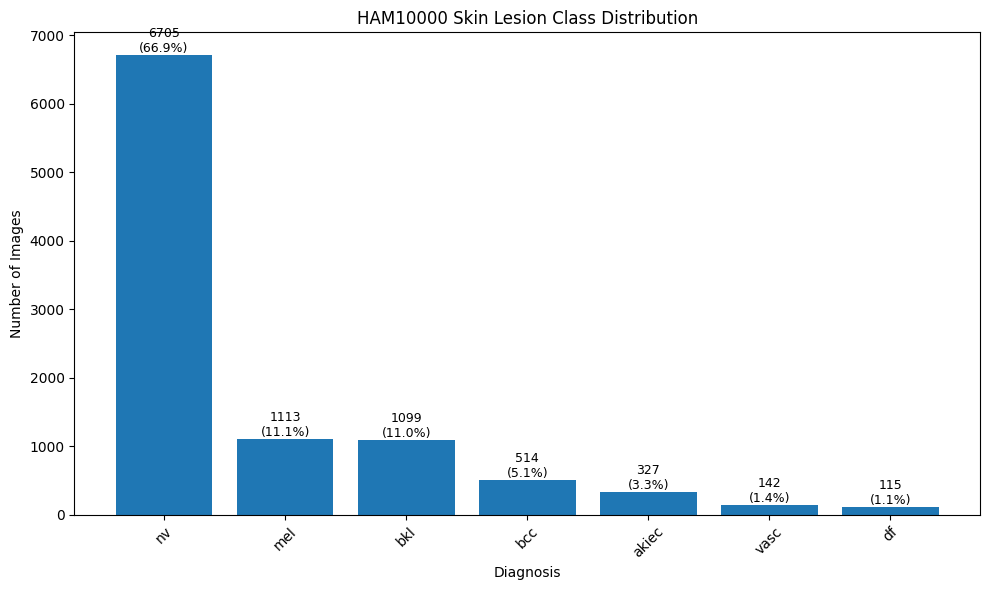

In [ ]:
import matplotlib.pyplot as plt

class_counts = df["dx"].value_counts()
class_percent = class_counts / class_counts.sum() * 100

plt.figure(figsize=(10, 6))

bars = plt.bar(class_counts.index, class_counts.values)

plt.title("HAM10000 Skin Lesion Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

for bar, count, percent in zip(
    bars, class_counts.values, class_percent.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count}\n({percent:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
import math

class_names = sorted(df["dx"].unique())

n_cols = 5
n_rows = len(class_names)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 4 * n_rows),
    squeeze=False
)

for i, diagnosis in enumerate(class_names):
    samples = df[df["dx"] == diagnosis].sample(
        n=min(5, len(df[df["dx"] == diagnosis])),
        random_state=42
    )

    for j, (_, row) in enumerate(samples.iterrows()):
        img = Image.open(row["path"]).convert("RGB")

        axes[i, j].imshow(img)
        axes[i, j].axis("off")
        axes[i, j].set_title(
            f"{row['dx']}\n{row['image_id']}",
            fontsize=9
        )

    # Hide unused image slots
    for j in range(len(samples), n_cols):
        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        diagnosis,
        fontsize=12,
        rotation=90,
        labelpad=15
    )

plt.suptitle(
    "HAM10000 Skin Lesion Images by Diagnosis",
    fontsize=18
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
print("Total metadata records:", len(df))
print("Images matched:", df["path"].notna().sum())
print("Images not matched:", df["path"].isna().sum())
print("Unique lesion IDs:", df["lesion_id"].nunique())

Total metadata records: 10015
Images matched: 10015
Images not matched: 0
Unique lesion IDs: 7470


,Column,Missing Count,Missing Percentage
0,lesion_id,0,0.000000
1,image_id,0,0.000000
2,dx,0,0.000000
3,dx_type,0,0.000000
4,age,57,0.569146
5,sex,0,0.000000
6,localization,0,0.000000
7,path,0,0.000000


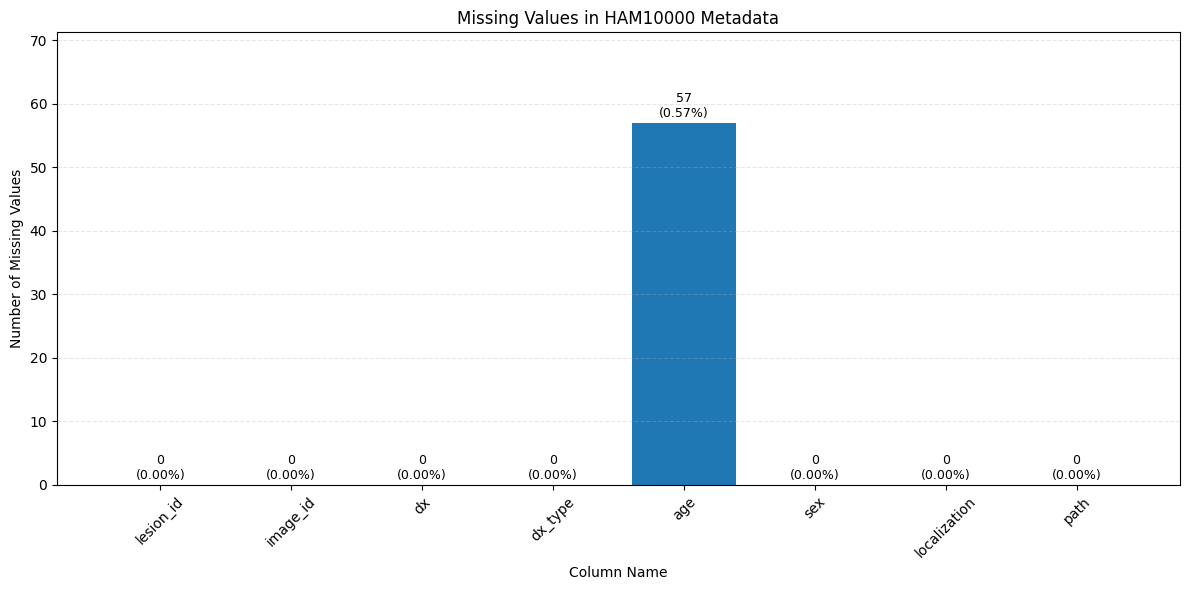

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

missing_df = pd.DataFrame({
    "Column": df.columns,
    "Missing Count": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().sum().values / len(df) * 100
    )
})

display(missing_df)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    missing_df["Column"],
    missing_df["Missing Count"]
)

ax.set_title("Missing Values in HAM10000 Metadata")
ax.set_xlabel("Column Name")
ax.set_ylabel("Number of Missing Values")
ax.tick_params(axis="x", rotation=45)

for bar, count, percent in zip(
    bars,
    missing_df["Missing Count"],
    missing_df["Missing Percentage"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{count}\n({percent:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(0, max(missing_df["Missing Count"].max() * 1.25, 5))
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

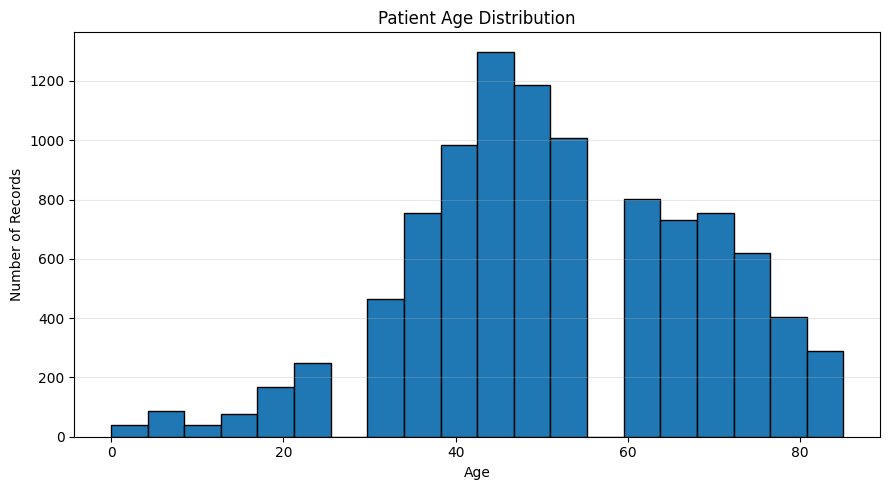

In [ ]:
ages = df["age"].dropna()

plt.figure(figsize=(9, 5))
plt.hist(ages, bins=20, edgecolor="black")
plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Records")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

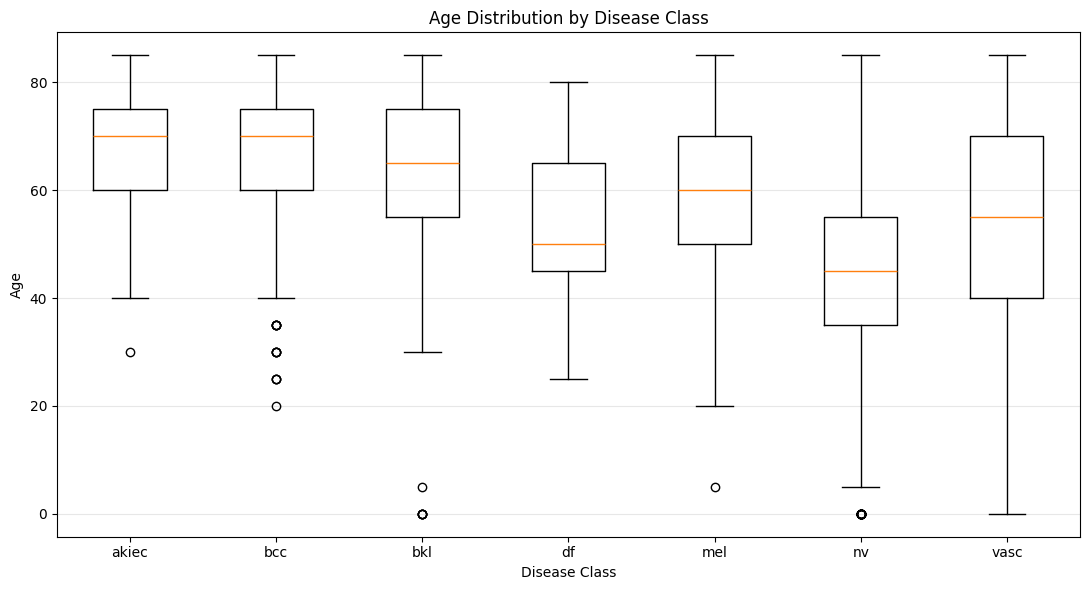

In [ ]:
plt.figure(figsize=(11, 6))

data = [
    df.loc[df["dx"] == disease, "age"].dropna()
    for disease in sorted(df["dx"].unique())
]

plt.boxplot(data, tick_labels=sorted(df["dx"].unique()))
plt.title("Age Distribution by Disease Class")
plt.xlabel("Disease Class")
plt.ylabel("Age")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

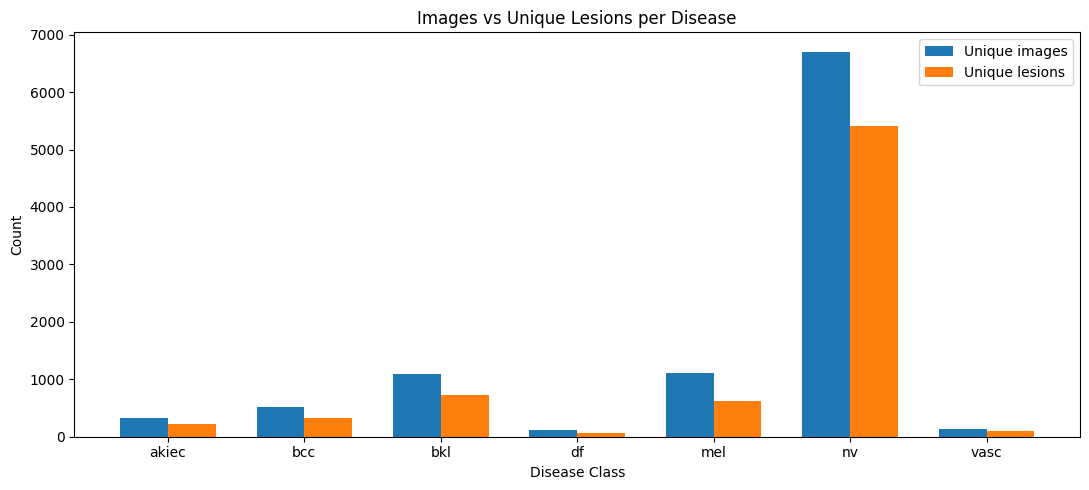

In [ ]:
image_counts = df.groupby("dx")["image_id"].nunique()
lesion_counts = df.groupby("dx")["lesion_id"].nunique()

x = range(len(image_counts))
width = 0.35

plt.figure(figsize=(11, 5))
plt.bar(
    [i - width / 2 for i in x],
    image_counts.values,
    width=width,
    label="Unique images"
)
plt.bar(
    [i + width / 2 for i in x],
    lesion_counts.reindex(image_counts.index).values,
    width=width,
    label="Unique lesions"
)

plt.xticks(list(x), image_counts.index)
plt.title("Images vs Unique Lesions per Disease")
plt.xlabel("Disease Class")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import os
from glob import glob

image_paths = (
    glob(os.path.join(BASE_DIR, "HAM10000_images_part_1", "*.jpg"))
    + glob(os.path.join(BASE_DIR, "HAM10000_images_part_2", "*.jpg"))
)

image_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

df["path"] = df["image_id"].map(image_map)

print("Total images found:", len(image_paths))
print("Metadata records:", len(df))
print("Matched images:", df["path"].notna().sum())
print("Unmatched records:", df["path"].isna().sum())

Total images found: 10015
Metadata records: 10015
Matched images: 10015
Unmatched records: 0


In [ ]:
import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/HAM10000"

train_df = pd.read_csv(
    os.path.join(BASE_DIR, "train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(BASE_DIR, "val_split.csv")
)

test_df = pd.read_csv(
    os.path.join(BASE_DIR, "test_split.csv")
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print(train_df.head())

Train: (7991, 7)
Validation: (1008, 7)
Test: (1016, 7)
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear


In [ ]:
print("Training classes:")
print(train_df["dx"].value_counts().sort_index())

print("\nValidation classes:")
print(val_df["dx"].value_counts().sort_index())

print("\nTesting classes:")
print(test_df["dx"].value_counts().sort_index())

Training classes:
dx
akiec     260
bcc       424
bkl       856
df         97
mel       877
nv       5369
vasc      108
Name: count, dtype: int64

Validation classes:
dx
akiec     26
bcc       36
bkl      133
df         8
mel      124
nv       663
vasc      18
Name: count, dtype: int64

Testing classes:
dx
akiec     41
bcc       54
bkl      110
df        10
mel      112
nv       673
vasc      16
Name: count, dtype: int64


In [ ]:
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

print("Train-Val overlap:", len(train_ids & val_ids))

print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class SkinLesionDataset(Dataset):
    def __init__(self, dataframe, transform, class_to_idx):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")
        image = self.transform(image)
        label = self.class_to_idx[row["dx"]]

        return image, label

In [ ]:
import torch

class_names = sorted(df["dx"].unique())
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

train_dataset = SkinLesionDataset(
    train_df, train_transform, class_to_idx
)

val_dataset = SkinLesionDataset(
    val_df, eval_transform, class_to_idx
)

test_dataset = SkinLesionDataset(
    test_df, eval_transform, class_to_idx
)

train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=32,
    shuffle=False, num_workers=2
)

print("Classes:", class_to_idx)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Classes: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Training samples: 7991
Validation samples: 1008
Test samples: 1016


In [ ]:
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Device available:", torch.cuda.is_available())

Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
Device available: True


In [ ]:
import torch
import numpy as np

class_names = [
    name for name, idx in sorted(
        class_to_idx.items(), key=lambda item: item[1]
    )
]

num_classes = len(class_names)

class_counts = (
    train_df["dx"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("Training images per class:")
print(class_counts)

if (class_counts == 0).any():
    raise ValueError("A class has no training images.")

weights = len(train_df) / (num_classes * class_counts)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class_weights = torch.tensor(
    weights.to_numpy(),
    dtype=torch.float32,
    device=device
)

print("\nClass weights:")
for name, weight in zip(class_names, class_weights.tolist()):
    print(f"{name}: {weight:.3f}")

print("\nNumber of classes:", num_classes)
print("Device:", device)

Training images per class:
dx
akiec     260
bcc       424
bkl       856
df         97
mel       877
nv       5369
vasc      108
Name: count, dtype: int64

Class weights:
akiec: 4.391
bcc: 2.692
bkl: 1.334
df: 11.769
mel: 1.302
nv: 0.213
vasc: 10.570

Number of classes: 7
Device: cuda


In [ ]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

model = model.to(device)

print(model.classifier)
print("Number of classes:", num_classes)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 103MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=7, bias=True)
)
Number of classes: 7
Device: cuda


In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

num_epochs = 10

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Epochs:", num_epochs)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Epochs: 10


In [ ]:

from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
import torch

best_val_f1 = -1.0
history = []

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print("-" * 50)

    model.train()
    train_loss_sum = 0.0
    train_true, train_pred = [], []

    train_bar = tqdm(
        train_loader,
        desc=f"Training Epoch {epoch + 1}/{num_epochs}",
        unit="batch"
    )

    for images, labels in train_bar:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.cpu().numpy())

        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_sum / len(train_loader.dataset)
    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(
        train_true, train_pred,
        average="macro", zero_division=0
    )

    model.eval()
    val_loss_sum = 0.0
    val_true, val_pred = [], []

    val_bar = tqdm(
        val_loader,
        desc=f"Validation Epoch {epoch + 1}/{num_epochs}",
        unit="batch"
    )

    with torch.no_grad():
        for images, labels in val_bar:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

            val_bar.set_postfix(loss=f"{loss.item():.4f}")

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro", zero_division=0
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(f"\nEpoch {epoch + 1}/{num_epochs} Results")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train Macro-F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation Macro-F1: {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(
            model.state_dict(),
            "/content/best_efficientnet_b0.pth"
        )
        print("Best model checkpoint saved.")

    print(f"Completed epoch {epoch + 1}/{num_epochs}")

print("\nTraining complete.")
print(f"Best validation Macro-F1: {best_val_f1:.4f}")



Epoch 1/10
--------------------------------------------------


Training Epoch 1/10:   0%|          | 0/250 [00:00<?, ?batch/s]

Validation Epoch 1/10:   0%|          | 0/32 [00:00<?, ?batch/s]


Epoch 1/10 Results
Train Loss: 1.3037
Train Accuracy: 0.5803
Train Macro-F1: 0.4059
Validation Loss: 0.9441
Validation Accuracy: 0.6776
Validation Macro-F1: 0.5249
Best model checkpoint saved.
Completed epoch 1/10

Epoch 2/10
--------------------------------------------------


Training Epoch 2/10:   0%|          | 0/250 [00:00<?, ?batch/s]

Validation Epoch 2/10:   0%|          | 0/32 [00:00<?, ?batch/s]

... (24 outputs left out)

Training Epoch 10/10:   0%|          | 0/250 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ad6ba86cb80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ad6ba86cb80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation Epoch 10/10:   0%|          | 0/32 [00:00<?, ?batch/s]


Epoch 10/10 Results
Train Loss: 0.2381
Train Accuracy: 0.8732
Train Macro-F1: 0.8434
Validation Loss: 0.6509
Validation Accuracy: 0.7927
Validation Macro-F1: 0.6320
Best model checkpoint saved.
Completed epoch 10/10

Training complete.
Best validation Macro-F1: 0.6320


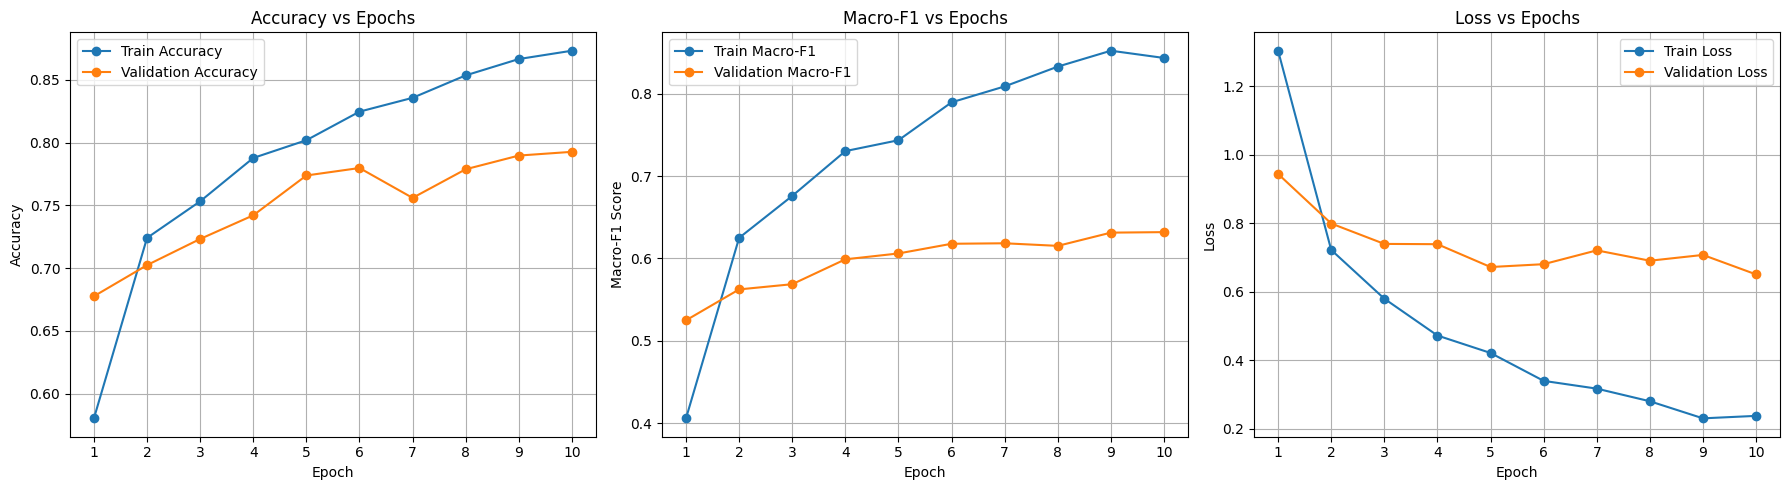

In [ ]:
import matplotlib.pyplot as plt

epochs = [item["epoch"] for item in history]

train_accuracy = [item["train_accuracy"] for item in history]
val_accuracy = [item["val_accuracy"] for item in history]

train_f1 = [item["train_macro_f1"] for item in history]
val_f1 = [item["val_macro_f1"] for item in history]

train_loss = [item["train_loss"] for item in history]
val_loss = [item["val_loss"] for item in history]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs, train_accuracy, marker="o", label="Train Accuracy")
axes[0].plot(epochs, val_accuracy, marker="o", label="Validation Accuracy")
axes[0].set_title("Accuracy vs Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(epochs)
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, train_f1, marker="o", label="Train Macro-F1")
axes[1].plot(epochs, val_f1, marker="o", label="Validation Macro-F1")
axes[1].set_title("Macro-F1 vs Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1 Score")
axes[1].set_xticks(epochs)
axes[1].legend()
axes[1].grid(True)

axes[2].plot(epochs, train_loss, marker="o", label="Train Loss")
axes[2].plot(epochs, val_loss, marker="o", label="Validation Loss")
axes[2].set_title("Loss vs Epochs")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].set_xticks(epochs)
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.savefig("/content/efficientnet_b0_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import os

print("Checkpoint exists:", os.path.exists("/content/best_efficientnet_b0.pth"))
print("Epochs recorded:", len(history))
print("Last epoch results:", history)

Checkpoint exists: True
Epochs recorded: 10
Last epoch results: [{'epoch': 1, 'train_loss': 1.3037125708209216, 'train_accuracy': 0.5802778125391065, 'train_macro_f1': 0.4058991956766088, 'val_loss': 0.9440569901277148, 'val_accuracy': 0.6775793650793651, 'val_macro_f1': 0.5249075703725639}, {'epoch': 2, 'train_loss': 0.7223160722992354, 'train_accuracy': 0.7240645726442247, 'train_macro_f1': 0.624992017365406, 'val_loss': 0.7994630890233176, 'val_accuracy': 0.7023809523809523, 'val_macro_f1': 0.5624229079890641}, {'epoch': 3, 'train_loss': 0.580053760738072, 'train_accuracy': 0.7532223751720686, 'train_macro_f1': 0.6759237018106993, 'val_loss': 0.7399112785619403, 'val_accuracy': 0.7232142857142857, 'val_macro_f1': 0.5687347067331384}, {'epoch': 4, 'train_loss': 0.4725487114356495, 'train_accuracy': 0.7877612313853085, 'train_macro_f1': 0.730304977356876, 'val_loss': 0.7390817556352842, 'val_accuracy': 0.7420634920634921, 'val_macro_f1': 0.5989395122273506}, {'epoch': 5, 'train_loss':

In [ ]:
checkpoint = torch.load(
    "/content/best_efficientnet_b0.pth",
    map_location=device,
    weights_only=True
)

print(type(checkpoint))

<class 'collections.OrderedDict'>


In [ ]:
model.load_state_dict(checkpoint)
model = model.to(device)
model.eval()

print("Best model loaded successfully")

Best model loaded successfully


Test Accuracy: 0.7746062992125984
Test Macro-F1: 0.6760243706391259

Classification Report:

              precision    recall  f1-score   support

       akiec       0.61      0.56      0.58        41
         bcc       0.65      0.85      0.74        54
         bkl       0.70      0.66      0.68       110
          df       0.64      0.70      0.67        10
         mel       0.42      0.71      0.53       112
          nv       0.94      0.81      0.87       673
        vasc       0.57      0.81      0.67        16

    accuracy                           0.77      1016
   macro avg       0.65      0.73      0.68      1016
weighted avg       0.82      0.77      0.79      1016



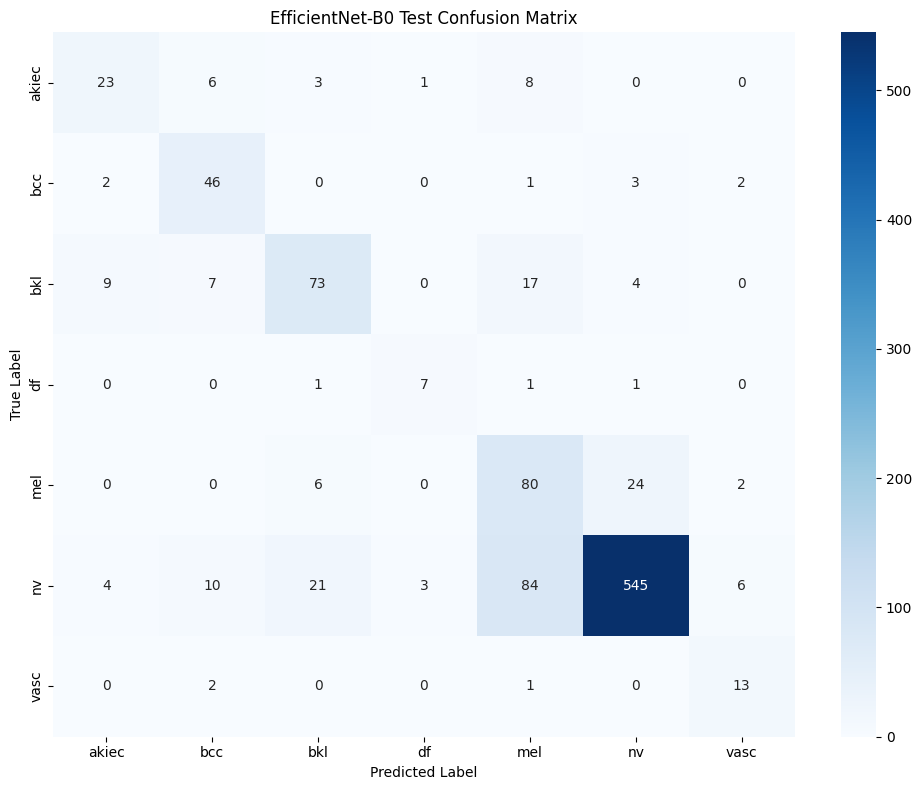

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

print("Test Accuracy:", accuracy_score(y_true, y_pred))
print("Test Macro-F1:", f1_score(y_true, y_pred, average="macro"))
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EfficientNet-B0 Test Confusion Matrix")
plt.tight_layout()
plt.show()

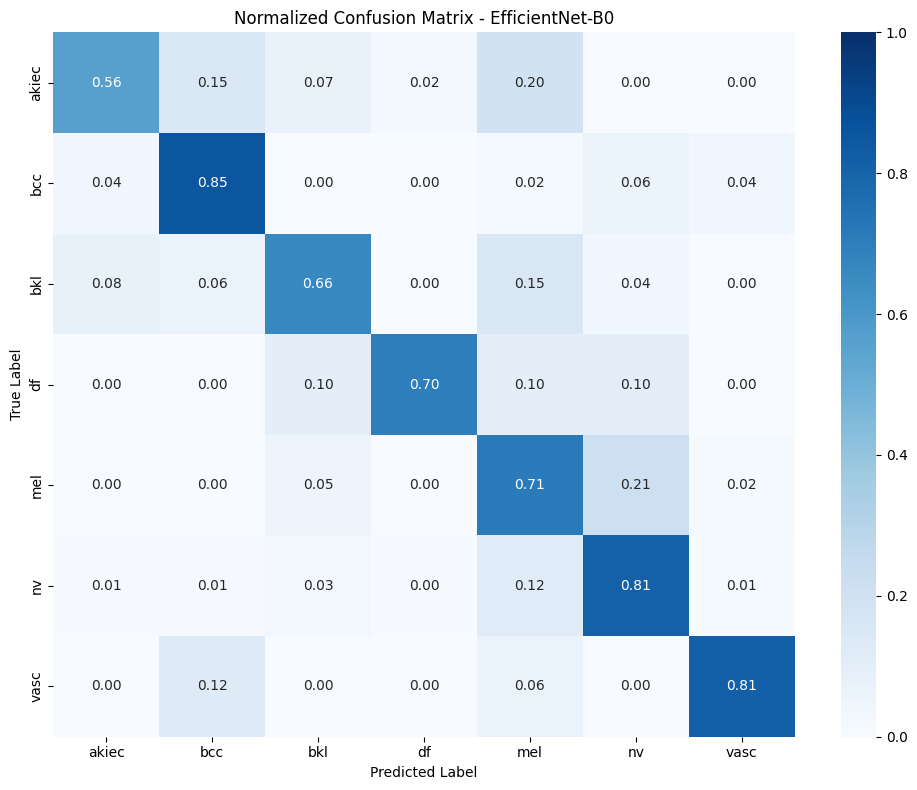

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized Confusion Matrix - EfficientNet-B0")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/HAM10000_Project"
os.makedirs(SAVE_DIR, exist_ok=True)

shutil.copy2(
    "/content/best_efficientnet_b0.pth",
    os.path.join(SAVE_DIR, "best_efficientnet_b0.pth")
)

print("Model saved to Google Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved to Google Drive


In [ ]:
import pandas as pd

history_df = pd.DataFrame(history)
history_df.to_csv(
    os.path.join(SAVE_DIR, "training_history.csv"),
    index=False
)

print("Training history saved")

Training history saved
